# How much of a coding-agent score is run-to-run luck?

- This notebook splits the score of 6 local coding agents (3 models x 2
  scaffolds) into the luck of the tasks and the luck of the runs, and checks
  which agents can be told apart
  - For now it reads the pilot scores: 20 HumanEval+ tasks, 2 runs at
    temperature 0.8
  - The full scores (HumanEval+ and MBPP+, 5 runs) replace them when the runs
    finish
- The pedagogical arc:
  - The agents and their scores
  - How much of the variance of 1 run is run-to-run luck
  - Which pairs of agents differ, over the tasks and the runs
  - How often a leaderboard from 1 run puts the agents in the wrong order
  - Whether more runs or more tasks help more

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp5ukgwnpw.json --HistoryManager.hist_file=:memory:


# Part 1: The agents and their scores

## Cell 1.1: Load the scores

- Each row is 1 solution: 1 model, 1 scaffold, 1 task, and 1 run
- The scaffolds share the first attempt, so `one_shot` and `repair` are paired

In [3]:
# Read the scores and the settings of the analysis.
SCORES_DIR = "data/coding_runs_pilot"
BENCHMARK = "humaneval"
TEMPERATURE = 0.8
scores = utils.load_scores(SCORES_DIR)

print("scores.shape=", scores.shape)
display(utils.compute_score_table(scores).round(3))
# Outcome: on these 20 easy tasks, the pilot pass rates at temperature 0.8 go
# from 82.5% (CodeQwen, one-shot) to 97.5% (OpenCoder).

scores.shape= (360, 19)


n_tasks  n_runs  base_pass  plus_pass  mean_attempts  mean_seconds
source benchmark model                               temperature scaffold                                                                    
local  humaneval codeqwen:7b-chat-v1.5-q4_K_M        0.0         one_shot       20       1      0.900      0.900          1.000        12.294
                                                                 repair         20       1      0.900      0.900          1.100        13.963
                                                     0.8         one_shot       20       2      0.850      0.825          1.000        11.922
                                                                 repair         20       2      0.875      0.850          1.175        14.432
                 deepseek-coder:1.3b-instruct-q4_K_M 0.0         one_shot       20       1      0.850      0.850          1.000         1.624
                                                                 repair         20       1      0.850      0.850          1.200         2.367
                                                     0.8         one_shot       20       2      0.850      0.850          1.000         1.481
                                                                 repair         20       2      0.925      0.925          1.125         1.708
                 opencoder:8b                        0.0         one_shot       20       1      1.000      1.000          1.000         9.018
                                                                 repair         20       1      1.000      1.000          1.000         9.018
                                                     0.8         one_shot       20       2      0.975      0.975          1.000         8.017
                                                                 repair         20       2      0.975      0.975          1.025         8.521

## Cell 1.2: Greedy scores against the published ones

- The greedy run (temperature 0) of each model checks the whole harness (the
  prompt, Ollama, and the scoring) against the published EvalPlus scores
- The published scores use full-precision weights, while these models run
  with 4-bit weights, so a few points of difference are expected

In [4]:
# Compare the greedy one-shot scores with the published ones.
validation = utils.compute_validation_table(scores)

display(validation.round(3))
# Outcome: the greedy scores are 11 to 25 points above the published ones, since
# the 20 pilot tasks are easier than the rest (the public CodeLlama-7B samples
# pass 60% of them and 34% of all 164): this check needs all the tasks.

,,n_tasks,base_pass,plus_pass,published_base,published_plus,plus_diff
model,benchmark,,,,,,
codeqwen:7b-chat-v1.5-q4_K_M,humaneval,20,0.90,0.90,0.835,0.787,0.113
deepseek-coder:1.3b-instruct-q4_K_M,humaneval,20,0.85,0.85,0.659,0.604,0.246
opencoder:8b,humaneval,20,1.00,1.00,0.817,0.774,0.226


## Cell 1.3: Failure modes

- Each failure is labeled by running the first failing input again
- A task flips for an agent when some of its runs pass and some fail
  - Those failures are run-to-run luck
  - A task that fails in every run is beyond the agent

In [5]:
# Count the failure modes of the sampled runs, by kind of task.
failures = utils.compute_failure_modes(
    scores, source="local", benchmark=BENCHMARK, temperature=TEMPERATURE
)

display(failures)
# Outcome: the tasks that always fail end in wrong answers only, while all the
# load and runtime errors come from tasks that flip; the repair scaffold removes
# the 2 load errors.

scaffold          one_shot             repair      
task          always_fails flips always_fails flips
failure                                            
load_error               0     2            0     0
runtime_error            0     2            0     2
wrong_answer             4     6            4     4

## Cell 1.4: Flaky tests

- Every solution is scored twice: a solution that passes once and fails once
  has a flaky test, which is luck of the environment, not of the model

In [6]:
# Compute the share of solutions whose 2 scorings disagree.
flaky_share = utils.compute_flaky_share(scores)

print("flaky_share=", flaky_share)
# Outcome: 0.0, no solution changed its result when scored again.

flaky_share= 0.0


# Part 2: How much of the variance is run-to-run luck?

## Cell 2.1: Task and run parts of the variance

- For each agent, the variance of a 1-run outcome splits into:
  - $\sigma^2_{task}$: how much the tasks differ in difficulty
  - $\sigma^2_{run}$: how much the outcome of 1 task changes between runs
- `run_share` is the part of a 1-run score's noise that more runs would remove

In [7]:
# Split the variance of every agent.
variance = utils.compute_variance_table(
    scores, source="local", benchmark=BENCHMARK, temperature=TEMPERATURE
)

display(variance.round(4))
# Outcome: with 2 runs on 20 tasks the split is rough, e.g., the task part of
# 4 agents is estimated at 0.

,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
opencoder / one_shot,0.975,0.0000,0.025,1.0000,0.0354,0.0250
opencoder / repair,0.975,0.0000,0.025,1.0000,0.0354,0.0250
deepseek-coder / repair,0.925,0.0000,0.075,1.0000,0.0612,0.0433
codeqwen / repair,0.850,0.0829,0.050,0.3762,0.0815,0.0734
deepseek-coder / one_shot,0.850,0.0000,0.150,1.0000,0.0866,0.0612
codeqwen / one_shot,0.825,0.0750,0.075,0.5000,0.0866,0.0750


## Cell 2.2: Plot of the 2 parts

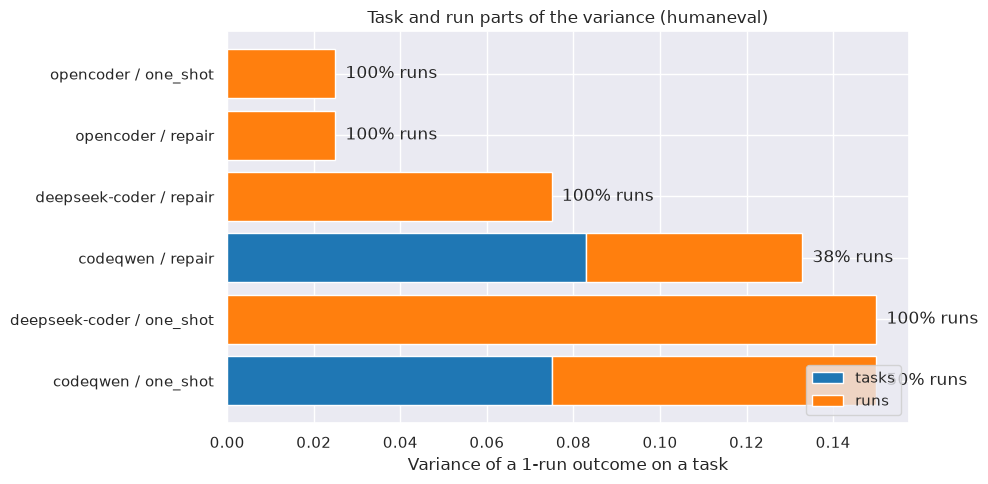

In [8]:
# Plot the task part and the run part of every agent.
utils.plot_variance_parts(
    variance,
    title=f"Task and run parts of the variance ({BENCHMARK})",
    figsize=(10, 5),
)

# Part 3: Which agents differ?

## Cell 3.1: Paired comparisons over tasks and runs

- The pre-registered family of comparisons:
  - The close pair (CodeQwen vs OpenCoder), for each scaffold
  - The weaker model (DeepSeek 1.3B) against each model of the pair
  - Repair against one-shot, for each model
- The Holm adjustment covers the whole family

In [9]:
# Compare the pre-registered pairs.
MODELS = {
    "deepseek": "deepseek-coder:1.3b-instruct-q4_K_M",
    "codeqwen": "codeqwen:7b-chat-v1.5-q4_K_M",
    "opencoder": "opencoder:8b",
}
pairs = []
for scaffold in ("one_shot", "repair"):
    pairs.append(
        ((MODELS["codeqwen"], scaffold), (MODELS["opencoder"], scaffold))
    )
    for strong in ("codeqwen", "opencoder"):
        pairs.append(
            ((MODELS[strong], scaffold), (MODELS["deepseek"], scaffold))
        )
for model in MODELS.values():
    pairs.append(((model, "repair"), (model, "one_shot")))
comparisons = utils.compare_agent_pairs(
    scores,
    pairs,
    source="local",
    benchmarks=[BENCHMARK],
    temperature=TEMPERATURE,
)

display(comparisons.round(4))
# Outcome: no comparison survives Holm on 20 tasks; the smallest raw p-value is
# 0.021 (OpenCoder vs DeepSeek, one-shot).

,benchmark,agent_a,agent_b,gap,ci_low,ci_high,gap_run_0,p_value,p_holm,distinguishable
0,humaneval,codeqwen / one_shot,opencoder / one_shot,-0.150,-0.300,-0.025,-0.20,0.0553,0.4421,False
1,humaneval,codeqwen / one_shot,deepseek-coder / one_shot,-0.025,-0.175,0.100,0.00,0.7157,1.0000,False
2,humaneval,opencoder / one_shot,deepseek-coder / one_shot,0.125,0.050,0.225,0.20,0.0210,0.1889,False
3,humaneval,codeqwen / repair,opencoder / repair,-0.125,-0.275,0.000,-0.15,0.0961,0.5797,False
4,humaneval,codeqwen / repair,deepseek-coder / repair,-0.075,-0.250,0.075,-0.05,0.3793,1.0000,False
5,humaneval,opencoder / repair,deepseek-coder / repair,0.050,0.000,0.125,0.10,0.1625,0.8127,False
6,humaneval,deepseek-coder / repair,deepseek-coder / one_shot,0.075,0.000,0.150,0.10,0.0828,0.5797,False
7,humaneval,codeqwen / repair,codeqwen / one_shot,0.025,0.000,0.075,0.05,0.3299,1.0000,False
8,humaneval,opencoder / repair,opencoder / one_shot,0.000,0.000,0.000,0.00,1.0000,1.0000,False


# Part 4: How stable is a leaderboard from 1 run?

## Cell 4.1: Order of the agents in random 1-run leaderboards

- A leaderboard usually runs each agent once
- Picking 1 run per agent at random shows how often that order matches the
  order over all the runs

In [10]:
# Draw random 1-run leaderboards.
matrices = utils.get_agent_matrices(
    scores, source="local", benchmark=BENCHMARK, temperature=TEMPERATURE
)
summary, flips = utils.compute_ranking_stability(matrices)

print("summary=", summary.round(3).to_dict())
display(flips.round(3))
# Outcome: only about half of the 1-run leaderboards (50.3%) keep the order of
# every pair whose means differ.

summary= {'p_same_order': 0.503, 'mean_kendall_tau': 0.816}


,upper,lower,gap,p_flip
0,opencoder / one_shot,opencoder / repair,0.000,0.498
1,deepseek-coder / one_shot,codeqwen / repair,0.000,0.497
2,codeqwen / repair,codeqwen / one_shot,0.025,0.249
3,deepseek-coder / one_shot,codeqwen / one_shot,0.025,0.374
4,opencoder / one_shot,deepseek-coder / repair,0.050,0.125
5,opencoder / repair,deepseek-coder / repair,0.050,0.123
6,deepseek-coder / repair,deepseek-coder / one_shot,0.075,0.127
7,deepseek-coder / repair,codeqwen / repair,0.075,0.000
8,deepseek-coder / repair,codeqwen / one_shot,0.100,0.000
9,opencoder / one_shot,deepseek-coder / one_shot,0.125,0.000


## Cell 4.2: Plot of the flip rate of each pair

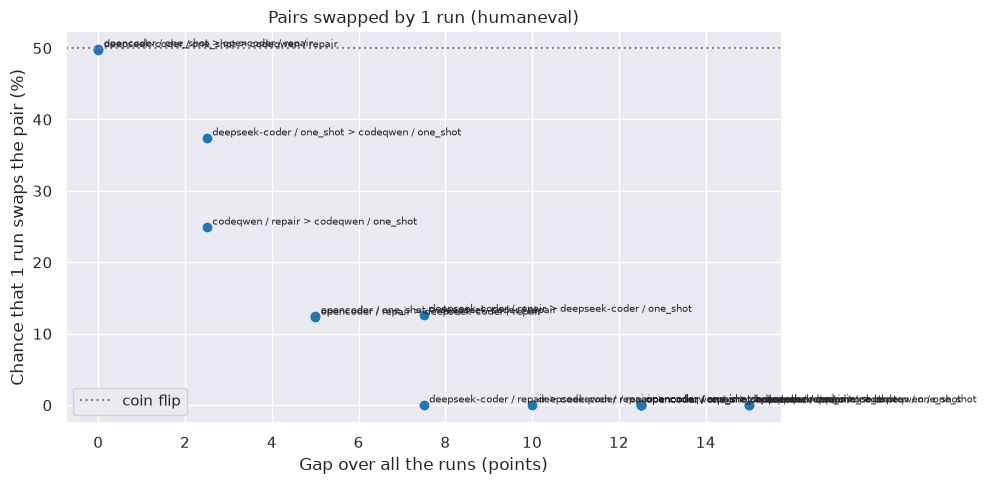

In [11]:
# Plot how often each pair swaps places, against its gap.
utils.plot_flip_rates(
    flips, title=f"Pairs swapped by 1 run ({BENCHMARK})", figsize=(10, 5)
)

# Part 5: More runs or more tasks?

## Cell 5.1: Tasks needed for a gap, by runs per task

- More runs only shrink the run part of the variance, so for the same number
  of evaluations, more tasks always help more than more runs
- The curves use the variance parts of the close pair with the one-shot
  scaffold

In [12]:
# Split the variance of the gap of the close pair.
parts = utils.compute_pair_variance_components(
    matrices["codeqwen / one_shot"], matrices["opencoder / one_shot"]
)

print("parts=", {key: round(value, 4) for key, value in parts.items()})
# Outcome: the run part of the gap variance (0.10) is larger than the task part
# (0.058) for this pair.

parts= {'sigma2_task_diff': 0.0579, 'sigma2_run_diff': 0.1}


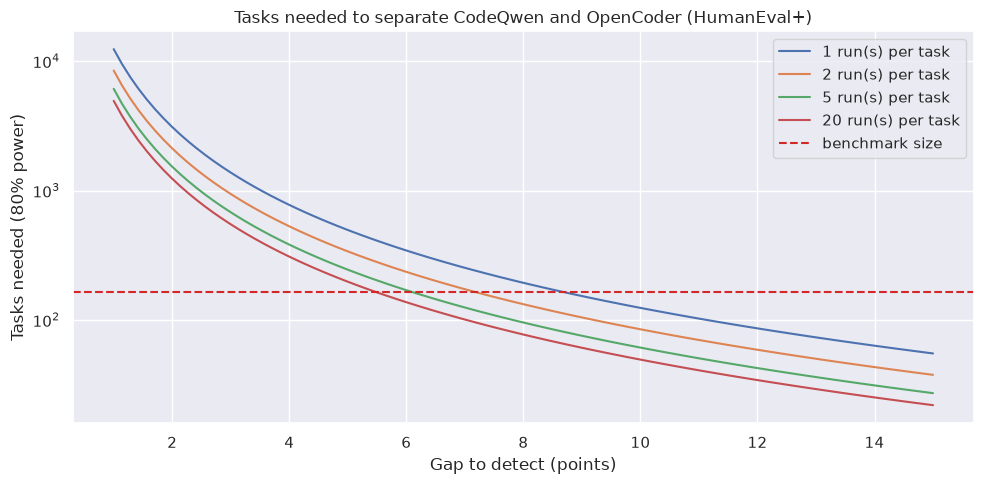

In [13]:
# Plot the tasks needed against the gap, for a few runs per task.
utils.plot_min_tasks_vs_runs(
    parts["sigma2_task_diff"],
    parts["sigma2_run_diff"],
    n_tasks=164,
    title="Tasks needed to separate CodeQwen and OpenCoder (HumanEval+)",
    figsize=(10, 5),
)